---
title: "Lab 9: Percent Body Fat"
author: "Shiqi Wu"
execute:
  warning: false
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

In [1]:
import pandas as pd

df_body_fat = pd.read_csv("NHANES_DXA_body_fat.csv")

print(df_body_fat.shape)
df_body_fat.head()

(2250, 18)


,RespondentID,AgeYears,SexRecorded,RaceEthnicityRecorded,EducationLevel,MaritalStatus,FamilyIncomePovertyRatio,Height_cm,Weight_kg,BMI_kg_m2,WaistCircumference_cm,DXAPercentBodyFat,SmokingStatus,UsualWeekdaySleepHours,AverageSystolicBP_mmHg,TotalCholesterol_mg_dL,HbA1c_percent,SelfRatedHealth
0,93711,56,Male,Non-Hispanic Asian,College graduate or above,Married/living with partner,5.00,170.6,62.1,21.3,86.6,22.8,Never,7.0,101.333333,238.0,5.7,Excellent
1,93714,54,Female,Non-Hispanic Black,Some college/AA,Married/living with partner,1.86,147.8,87.1,39.9,118.4,42.1,Former,7.0,162.000000,230.0,12.7,Good
2,93717,22,Male,Non-Hispanic White,High school/GED,NaN,1.49,174.1,74.4,24.5,86.2,20.4,Current,8.0,118.666667,213.0,5.1,Very good
3,93729,42,Male,Non-Hispanic Black,9th-11th grade,NaN,0.83,173.2,82.8,27.6,101.5,29.4,Current,9.0,126.000000,165.0,5.3,Good
4,93730,57,Male,Other Hispanic,9th-11th grade,Widowed/divorced/separated,NaN,167.6,80.2,28.6,96.3,22.8,Never,7.0,132.666667,221.0,13.3,Fair


In [2]:
missing_counts = df_body_fat.isna().sum()

missing_counts[missing_counts > 0].sort_values(ascending=False)

MaritalStatus               944
FamilyIncomePovertyRatio    249
TotalCholesterol_mg_dL      108
HbA1c_percent                78
AverageSystolicBP_mmHg       75
WaistCircumference_cm        22
UsualWeekdaySleepHours       14
BMI_kg_m2                    10
Height_cm                     9
Weight_kg                     8
SelfRatedHealth               5
dtype: int64

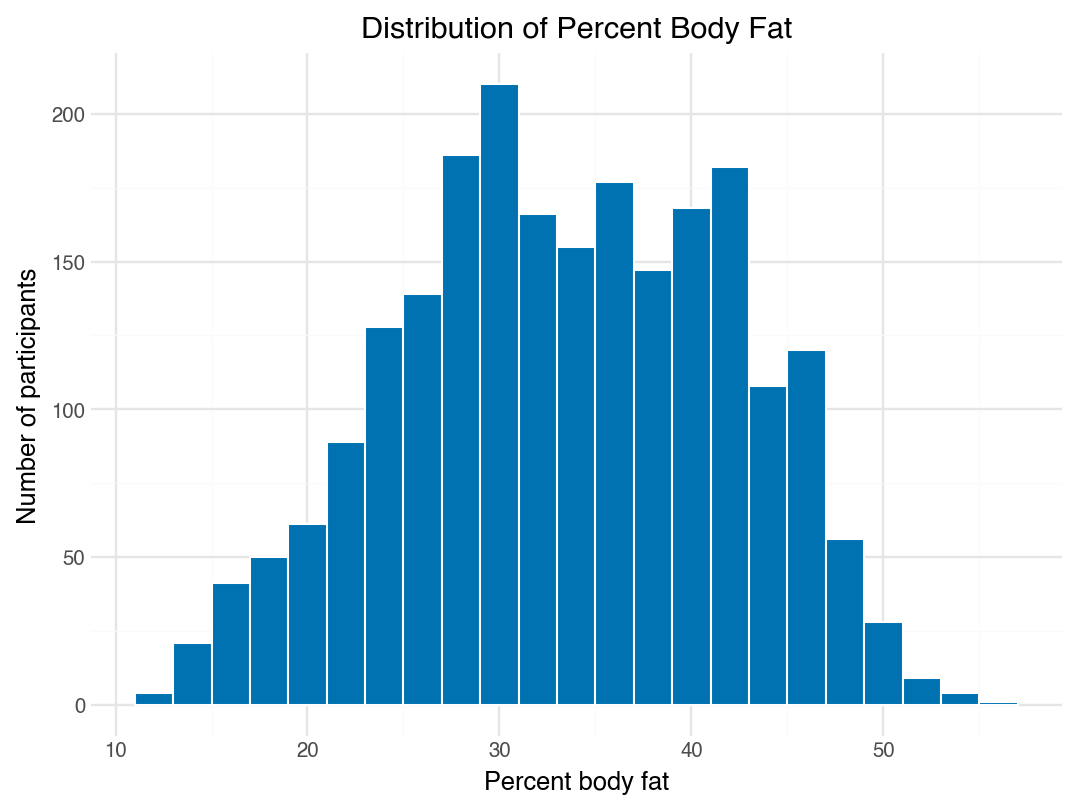

In [3]:
from plotnine import aes, geom_histogram, ggplot, labs, theme_minimal

(
    ggplot(df_body_fat, aes(x="DXAPercentBodyFat"))
    + geom_histogram(binwidth=2, fill="#0072B2", color="white")
    + labs(
        title="Distribution of Percent Body Fat",
        x="Percent body fat",
        y="Number of participants"
    )
    + theme_minimal()
)

**Answer:** The dataset includes 2250 participants. Most body fat percentages are between about 25% and 45%, with the tallest bar near 30%. The target variable has no missing values. Marital status has the most missing values, with 944 out of 2250.

In [4]:
X = df_body_fat.drop(columns=["RespondentID", "DXAPercentBodyFat"])
y = df_body_fat["DXAPercentBodyFat"]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (2250, 16)
Target shape: (2250,)


In [5]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

categorical_pipeline = make_pipeline(
    SimpleImputer(strategy="constant", fill_value="Missing"),
    OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)
)

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, make_column_selector(dtype_include="number")),
    ("categorical", categorical_pipeline, make_column_selector(dtype_exclude="number"))
])

**Answer:** We kept all 2250 observations and left out `RespondentID` because it is only used to link records. We fill missing numeric values with the median and then standardize the numeric predictors. For categorical predictors, we label missing values as `Missing` and use dummy variables. In cross-validation, each fold learns its preprocessing settings from its training data.

## Part I: Different Model Specs

### Linear regression without regularization

In [7]:
from sklearn.linear_model import LinearRegression

linear_model = make_pipeline(preprocessor, LinearRegression())
linear_model.fit(X, y)

linear_coefficients = pd.Series(
    linear_model.named_steps["linearregression"].coef_,
    index=linear_model.named_steps["columntransformer"].get_feature_names_out()
)

linear_coefficients.sort_values(key=abs, ascending=False).head(8).round(3)

categorical__SexRecorded_Male                           -10.889
numeric__WaistCircumference_cm                            4.698
categorical__SelfRatedHealth_Missing                      3.889
categorical__MaritalStatus_Refused                       -1.967
categorical__EducationLevel_Refused                      -1.967
numeric__BMI_kg_m2                                        1.568
categorical__RaceEthnicityRecorded_Non-Hispanic Black    -1.379
numeric__Weight_kg                                       -0.999
dtype: float64

In [8]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=10, shuffle=True, random_state=42)

linear_rmse = -cross_val_score(
    linear_model, X, y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

print(f"Mean cross-validated RMSE: {linear_rmse.mean():.3f}")

Mean cross-validated RMSE: 3.673


/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros


**Answer:** Holding the other predictors fixed, the model predicted that males had 10.89 percentage points lower body fat than females. A one-standard-deviation increase in waist circumference was associated with a 4.70 percentage point increase in predicted body fat. For BMI, the corresponding increase was 1.57 percentage points. The mean RMSE across the 10 validation folds was 3.673 percentage points of body fat.

### Ridge regression

In [9]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

ridge_grid = GridSearchCV(
    make_pipeline(preprocessor, Ridge()),
    param_grid={"ridge__alpha": np.logspace(-3, 3, 13)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

ridge_grid.fit(X, y)

print("Best alpha:", ridge_grid.best_params_["ridge__alpha"])
print(f"Best mean CV RMSE: {-ridge_grid.best_score_:.4f}")

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.

Best alpha: 1.0
Best mean CV RMSE: 3.6729


In [11]:
ridge_model = ridge_grid.best_estimator_

ridge_coefficients = pd.Series(
    ridge_model.named_steps["ridge"].coef_,
    index=ridge_model.named_steps["columntransformer"].get_feature_names_out()
)

ridge_comparison = pd.DataFrame({
    "Linear regression": linear_coefficients,
    "Ridge regression": ridge_coefficients
})
ridge_top_features = ridge_coefficients.abs().nlargest(8).index

ridge_comparison.loc[ridge_top_features].round(3)

,Linear regression,Ridge regression
categorical__SexRecorded_Male,-10.889,-10.845
numeric__WaistCircumference_cm,4.698,4.683
categorical__SelfRatedHealth_Missing,3.889,3.221
numeric__BMI_kg_m2,1.568,1.496
categorical__RaceEthnicityRecorded_Non-Hispanic Black,-1.379,-1.364
categorical__EducationLevel_Refused,-1.967,-1.311
categorical__MaritalStatus_Refused,-1.967,-1.311
categorical__SelfRatedHealth_Fair,0.978,0.954


**Answer:** Ridge selected an alpha of 1.0. Holding the other predictors fixed, the model predicted 10.85 percentage points lower body fat for males than for females. A one-standard-deviation increase in waist circumference was associated with 4.68 percentage points higher predicted body fat. For BMI, the corresponding increase was 1.50 percentage points. All three coefficients moved slightly toward zero compared with ordinary linear regression. The mean RMSE across the 10 validation folds was 3.6729 percentage points of body fat, almost the same as for ordinary linear regression.

### LASSO regression

In [12]:
from sklearn.linear_model import Lasso

lasso_grid = GridSearchCV(
    make_pipeline(preprocessor, Lasso(max_iter=10000)),
    param_grid={"lasso__alpha": np.logspace(-4, 0, 17)},
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

lasso_grid.fit(X, y)

print(f"Best alpha: {lasso_grid.best_params_['lasso__alpha']:.6f}")
print(f"Best mean CV RMSE: {-lasso_grid.best_score_:.4f}")

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.

Best alpha: 0.000562
Best mean CV RMSE: 3.6730


In [13]:
lasso_model = lasso_grid.best_estimator_

lasso_coefficients = pd.Series(
    lasso_model.named_steps["lasso"].coef_,
    index=lasso_model.named_steps["columntransformer"].get_feature_names_out()
)

print("Coefficients set to zero:", lasso_coefficients[lasso_coefficients == 0].index.tolist())
lasso_coefficients.sort_values(key=abs, ascending=False).head(8).round(3)

Coefficients set to zero: ['categorical__MaritalStatus_Refused']


categorical__SexRecorded_Male                           -10.884
numeric__WaistCircumference_cm                            4.696
categorical__SelfRatedHealth_Missing                      3.612
categorical__EducationLevel_Refused                      -2.667
numeric__BMI_kg_m2                                        1.493
categorical__RaceEthnicityRecorded_Non-Hispanic Black    -1.363
categorical__SelfRatedHealth_Fair                         0.947
numeric__Weight_kg                                       -0.913
dtype: float64

**Answer:** LASSO selected an alpha of about 0.000562. Holding the other predictors fixed, the model predicted 10.88 percentage points lower body fat for males than for females. A one-standard-deviation increase in waist circumference was associated with 4.70 percentage points higher predicted body fat. For BMI, the corresponding increase was 1.49 percentage points. LASSO set the coefficient for `MaritalStatus_Refused` to zero. The two `Refused` indicators for marital status and education identified the same participant. The mean RMSE across the 10 validation folds was 3.6730 percentage points of body fat.

### Elastic net regression

In [14]:
from sklearn.linear_model import ElasticNet

elastic_grid = GridSearchCV(
    make_pipeline(preprocessor, ElasticNet(max_iter=10000)),
    param_grid={
        "elasticnet__alpha": np.logspace(-4, 0, 17),
        "elasticnet__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    },
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

elastic_grid.fit(X, y)

print(f"Best alpha: {elastic_grid.best_params_['elasticnet__alpha']:.6f}")
print(f"Best l1_ratio: {elastic_grid.best_params_['elasticnet__l1_ratio']}")
print(f"Best mean CV RMSE: {-elastic_grid.best_score_:.4f}")

/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros
/Users/shiqi/miniforge3/envs/datamining/lib/python3.

Best alpha: 0.000562
Best l1_ratio: 0.1
Best mean CV RMSE: 3.6729


In [15]:
elastic_model = elastic_grid.best_estimator_

elastic_coefficients = pd.Series(
    elastic_model.named_steps["elasticnet"].coef_,
    index=elastic_model.named_steps["columntransformer"].get_feature_names_out()
)

print("Number of zero coefficients:", (elastic_coefficients == 0).sum())
elastic_coefficients.sort_values(key=abs, ascending=False).head(8).round(3)

Number of zero coefficients: 0


categorical__SexRecorded_Male                           -10.839
numeric__WaistCircumference_cm                            4.680
categorical__SelfRatedHealth_Missing                      3.123
numeric__BMI_kg_m2                                        1.480
categorical__RaceEthnicityRecorded_Non-Hispanic Black    -1.361
categorical__MaritalStatus_Refused                       -1.213
categorical__EducationLevel_Refused                      -1.213
categorical__SelfRatedHealth_Fair                         0.948
dtype: float64

**Answer:** Elastic Net selected an alpha of about 0.000562 and an `l1_ratio` of 0.1. Holding the other predictors fixed, the model predicted 10.84 percentage points lower body fat for males than for females. A one-standard-deviation increase in waist circumference was associated with 4.68 percentage points higher predicted body fat. For BMI, the corresponding increase was 1.48 percentage points. All 32 fitted coefficients were nonzero. The mean RMSE across the 10 validation folds was 3.6729 percentage points of body fat.

## Part II. Variable Selection

**Answer:** We used the Ridge results from Part I to choose predictors. The numeric predictors were standardized, so we ranked them by the absolute size of their coefficients. Waist circumference ranked first. The top five were waist circumference, BMI, weight, height, and age. For each categorical predictor, we looked at its largest absolute dummy coefficient. Recorded sex ranked first, so we selected it for the interactions.

In [16]:
numeric_ridge = ridge_coefficients.filter(like="numeric__")
top_five = numeric_ridge.abs().nlargest(5)
best_numeric = top_five.index.str.removeprefix("numeric__").tolist()
best_categorical = "SexRecorded"

X_one = X[[best_numeric[0]]]
X_five = X[best_numeric]
X_five_with_sex = X[best_numeric + [best_categorical]]

print("Best numeric predictor:", best_numeric[0])
print("Top five numeric predictors:", best_numeric)
print("Categorical predictor for interactions:", best_categorical)

Best numeric predictor: WaistCircumference_cm
Top five numeric predictors: ['WaistCircumference_cm', 'BMI_kg_m2', 'Weight_kg', 'Height_cm', 'AgeYears']
Categorical predictor for interactions: SexRecorded


In [17]:
from sklearn.base import clone
from sklearn.preprocessing import FunctionTransformer

interaction_names = [f"{name}_x_Male" for name in best_numeric]

def add_sex_interactions(features):
    features = features.copy()
    male = features["categorical__SexRecorded_Male"]
    for name in best_numeric:
        features[f"{name}_x_Male"] = features[f"numeric__{name}"] * male
    return features

interaction_preprocessor = make_pipeline(
    clone(preprocessor).set_output(transform="pandas"),
    FunctionTransformer(add_sex_interactions),
    ColumnTransformer(
        [("interactions", StandardScaler(), interaction_names)],
        remainder="passthrough"
    )
)

print("Interaction terms:", interaction_names)

Interaction terms: ['WaistCircumference_cm_x_Male', 'BMI_kg_m2_x_Male', 'Weight_kg_x_Male', 'Height_cm_x_Male', 'AgeYears_x_Male']


In [18]:
feature_sets = {
    "One numeric predictor": (X_one, preprocessor),
    "Five numeric predictors": (X_five, preprocessor),
    "Five numeric predictors with sex interactions": (X_five_with_sex, interaction_preprocessor)
}

linear_subset_models = {}
linear_subset_rmse = {}

for name, (X_subset, prep) in feature_sets.items():
    model = make_pipeline(clone(prep), LinearRegression())
    model.fit(X_subset, y)
    linear_subset_models[name] = model

    scores = -cross_val_score(
        model, X_subset, y, cv=cv, scoring="neg_root_mean_squared_error"
    )
    linear_subset_rmse[name] = scores.mean()

pd.Series(linear_subset_rmse, name="Mean CV RMSE").round(4)

One numeric predictor                            7.3794
Five numeric predictors                          5.4652
Five numeric predictors with sex interactions    3.6969
Name: Mean CV RMSE, dtype: float64

In [19]:
def tune_feature_sets(estimator, param_grid):
    searches = {}
    results = []

    for name, (X_subset, prep) in feature_sets.items():
        search = GridSearchCV(
            make_pipeline(clone(prep), clone(estimator)),
            param_grid=param_grid,
            cv=cv,
            scoring="neg_root_mean_squared_error"
        )
        search.fit(X_subset, y)
        searches[name] = search
        results.append({
            "Feature set": name,
            **search.best_params_,
            "Mean CV RMSE": -search.best_score_
        })

    return searches, pd.DataFrame(results)

ridge_subset_grids, ridge_subset_results = tune_feature_sets(
    Ridge(), ridge_grid.param_grid
)

ridge_subset_results.rename(columns={"ridge__alpha": "Best alpha"}).round(4)

,Feature set,Best alpha,Mean CV RMSE
0,One numeric predictor,3.1623,7.3794
1,Five numeric predictors,10.0000,5.4646
2,Five numeric predictors with sex interactions,3.1623,3.6947


In [20]:
lasso_subset_grids, lasso_subset_results = tune_feature_sets(
    Lasso(max_iter=10000), lasso_grid.param_grid
)

lasso_subset_results.rename(columns={"lasso__alpha": "Best alpha"}).round({
    "Best alpha": 6,
    "Mean CV RMSE": 4
})

,Feature set,Best alpha,Mean CV RMSE
0,One numeric predictor,0.001000,7.3794
1,Five numeric predictors,0.031623,5.4640
2,Five numeric predictors with sex interactions,0.010000,3.6951


In [21]:
elastic_subset_grids, elastic_subset_results = tune_feature_sets(
    ElasticNet(max_iter=10000), elastic_grid.param_grid
)

elastic_subset_results.rename(columns={
    "elasticnet__alpha": "Best alpha",
    "elasticnet__l1_ratio": "Best l1_ratio"
}).round({
    "Best alpha": 6,
    "Mean CV RMSE": 4
})

,Feature set,Best alpha,Best l1_ratio,Mean CV RMSE
0,One numeric predictor,0.001000,0.1,7.3794
1,Five numeric predictors,0.010000,0.9,5.4642
2,Five numeric predictors with sex interactions,0.001778,0.1,3.6947


In [22]:
part2_rmse = pd.DataFrame({
    "Linear regression": pd.Series(linear_subset_rmse),
    "Ridge": ridge_subset_results.set_index("Feature set")["Mean CV RMSE"],
    "LASSO": lasso_subset_results.set_index("Feature set")["Mean CV RMSE"],
    "Elastic Net": elastic_subset_results.set_index("Feature set")["Mean CV RMSE"]
}).rename_axis("Feature set")

part2_ranked = (
    part2_rmse.reset_index()
    .melt(id_vars="Feature set", var_name="Model", value_name="Mean CV RMSE")
    .sort_values("Mean CV RMSE", ignore_index=True)
)

part2_ranked.round({"Mean CV RMSE": 6})

,Feature set,Model,Mean CV RMSE
0,Five numeric predictors with sex interactions,Elastic Net,3.694685
1,Five numeric predictors with sex interactions,Ridge,3.694688
2,Five numeric predictors with sex interactions,LASSO,3.695066
3,Five numeric predictors with sex interactions,Linear regression,3.696905
4,Five numeric predictors,LASSO,5.464049
5,Five numeric predictors,Elastic Net,5.464151
6,Five numeric predictors,Ridge,5.464570
7,Five numeric predictors,Linear regression,5.465234
8,One numeric predictor,Ridge,7.379438
9,One numeric predictor,Elastic Net,7.379438


**Answer:** Among the 12 combinations in Part II, Elastic Net with the five numeric predictors, recorded sex, and the five interaction terms had the lowest mean cross-validation RMSE at 3.694685 percentage points. Ridge with the same predictors was almost identical at 3.694688 percentage points. For all four models, the feature set with recorded sex and the interactions gave the lowest RMSE.

## Part III. Discussion

### 1. Ridge versus ordinary linear regression

**Answer:** We compared Ridge and ordinary linear regression using the same predictors in each of the four comparisons. The Ridge coefficients were smaller overall. In the full model, the waist circumference coefficient went from 4.698 to 4.683, and the coefficient for males moved from −10.889 to −10.845. This makes sense because Ridge adds a penalty based on the sum of the squared coefficients. Some individual coefficients can still increase when correlated predictors share the work of making predictions.

### 2. LASSO in Part I and Part II

**Answer:** We found different best alpha values for the four LASSO models. The best alpha was 0.000562 for the full model, 0.001 for the one-predictor model, 0.031623 for the five-predictor model, and 0.01 for the model with five numeric predictors, recorded sex, and their interactions. This makes sense because changing the predictors can change how much shrinkage works best.

The mean cross-validation RMSEs were 3.6730, 7.3794, 5.4640, and 3.6951 percentage points, respectively. The model using only waist circumference had the largest error. Adding more predictors lowered the error, and including recorded sex and its interactions brought the RMSE close to that of the full model.

### 3. Elastic Net compared with LASSO and Ridge

**Answer:** With all predictors, Elastic Net and Ridge both had a mean cross-validation RMSE of about 3.6729 percentage points. LASSO was very close at 3.6730. Elastic Net put more weight on the Ridge penalty and kept all 32 coefficients nonzero. LASSO set one coefficient to zero.

In Part II, Elastic Net had the lowest RMSE for the feature set with recorded sex and the interaction terms, but Ridge and LASSO were very close. Overall, changing the predictors made a much bigger difference in RMSE than switching between the three methods.

## Part IV: Final Model

In [23]:
final_model = clone(elastic_grid.best_estimator_)
final_model.fit(X, y)

final_params = final_model.get_params()

print("Final model: Elastic Net with all predictors")
print(f"Training observations: {len(y)}")
print(f"Alpha: {final_params['elasticnet__alpha']:.6f}")
print(f"L1 ratio: {final_params['elasticnet__l1_ratio']}")
print(f"Mean cross-validation RMSE: {-elastic_grid.best_score_:.4f}")

Final model: Elastic Net with all predictors
Training observations: 2250
Alpha: 0.000562
L1 ratio: 0.1
Mean cross-validation RMSE: 3.6729


/Users/shiqi/miniforge3/envs/datamining/lib/python3.11/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [2, 3] during transform. These unknown categories will be encoded as all zeros


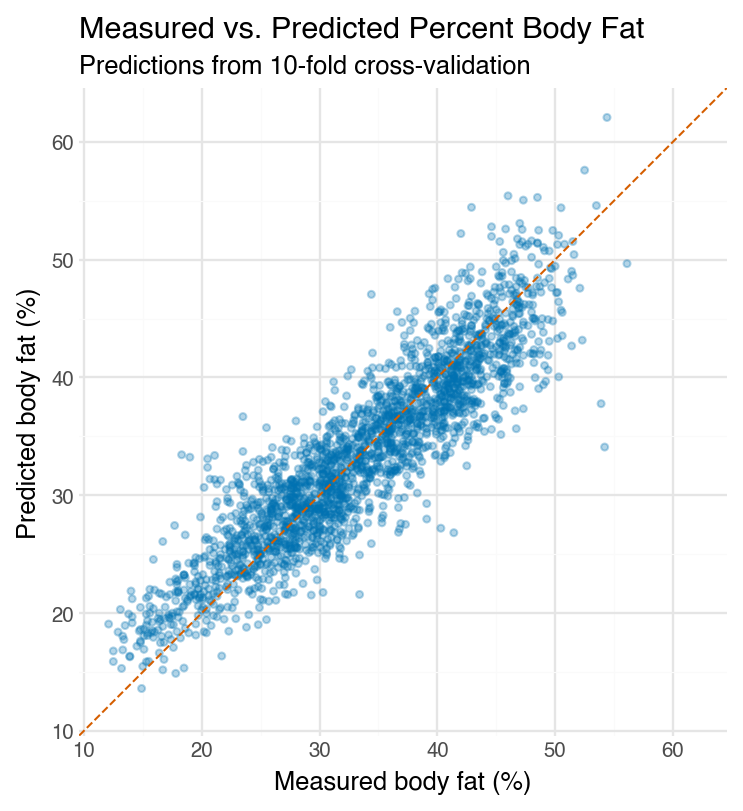

In [24]:
from plotnine import coord_equal, geom_abline, geom_point
from sklearn.model_selection import cross_val_predict

cv_predictions = cross_val_predict(final_model, X, y, cv=cv)

final_plot_data = pd.DataFrame({
    "Measured": y.to_numpy(),
    "Predicted": cv_predictions
})
plot_limits = (
    final_plot_data.min().min(),
    final_plot_data.max().max()
)

(
    ggplot(final_plot_data, aes(x="Measured", y="Predicted"))
    + geom_point(alpha=0.3, size=1.2, color="#0072B2")
    + geom_abline(intercept=0, slope=1, linetype="dashed", color="#D55E00")
    + coord_equal(xlim=plot_limits, ylim=plot_limits)
    + labs(
        title="Measured vs. Predicted Percent Body Fat",
        subtitle="Predictions from 10-fold cross-validation",
        x="Measured body fat (%)",
        y="Predicted body fat (%)"
    )
    + theme_minimal()
)

**Answer:** We chose Elastic Net with all predictors and fitted it to all 2250 observations. Its mean RMSE across the 10 validation folds was 3.67 percentage points of body fat. The predictions generally follow the diagonal line, although some are far from the measured values. In Part II, adding more body measurements lowered the error compared with using waist circumference alone. Adding recorded sex and its interactions lowered the error further. We used the same cross-validation folds to choose the model and estimate its error, so the reported RMSE may be slightly optimistic.